# 02. Modeling

Notebook ini berisi proses pengembangan model klasifikasi gambar dokumen menggunakan EfficientNet-B0 berbasis PyTorch. Model digunakan untuk mengklasifikasikan gambar ke dalam 16 kategori dokumen.

Tahapan modeling meliputi **persiapan data > pembuatan model baseline > hyperparameter tuning > fine-tuning > evaluasi > Test-Time Augmentation (TTA).**

Proses training dan evaluasi menggunakan fungsi yang telah dipisahkan ke dalam folder `scripts/` agar kode lebih terstruktur dan dapat digunakan kembali.

## 1. Environment Setup

In [ ]:
from pathlib import Path
import sys
import zipfile

WORK_DIR = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path.cwd()

def add_project_scripts():
    search_dirs = [Path.cwd(), Path.cwd().parent, WORK_DIR]
    for parent in search_dirs:
        if (parent / 'scripts' / 'dataset.py').is_file():
            sys.path.insert(0, str(parent.resolve()))
            return parent
    input_dir = Path('/kaggle/input')
    if input_dir.exists():
      
        for file in sorted(input_dir.rglob('scripts/dataset.py')):
            parent = file.parent.parent
            sys.path.insert(0, str(parent))
            return parent
        
        archives = sorted(input_dir.rglob('scripts.zip'))
        if archives:
            destination = WORK_DIR / 'project_code'
            destination.mkdir(parents=True, exist_ok=True)
            with zipfile.ZipFile(archives[0]) as archive:
                archive.extractall(destination)
            if not (destination / 'scripts' / 'dataset.py').is_file():
                raise FileNotFoundError('scripts.zip must contain scripts/dataset.py')
            sys.path.insert(0, str(destination))
            return destination
    raise FileNotFoundError(
        'scripts package not found. Attach scripts.zip through Kaggle Add Input, '
        'or run this notebook inside the GitHub project directory.')

PROJECT_CODE = add_project_scripts()
print('Scripts loaded from:', PROJECT_CODE)

Scripts loaded from: /kaggle/input/datasets/sharlizmayz/scripts-document-classification


In [ ]:
import gc
import random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from scripts.dataset import (
    find_data_dir, load_metadata, make_train_val_split,
    find_image_root, make_loader, split_fingerprint,)
from scripts.model import build_b0, locate_pretrained_weights
from scripts.train import TrainConfig, set_seed, run_experiment, paths_for_run
from scripts.evaluate import load_model, evaluate_model, plot_history

from sklearn.metrics import classification_report, confusion_matrix

SEED = 42
IMAGE_SIZE = 224
BATCH_SIZE = 16
NUM_WORKERS = 0              # Safe default  
RUN_EXPERIMENTS = True        # False = evaluate existing checkpoints only
CHECKPOINT_OVERRIDE = None    # Optional path to an already trained B0 best.pt

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
OUTPUT_DIR = (
    Path('/kaggle/working')
    if Path('/kaggle/working').exists()
    else Path(PROJECT_CODE) / 'outputs')
CHECKPOINT_DIR = OUTPUT_DIR / 'checkpoints'
REPORT_DIR = OUTPUT_DIR / 'reports'
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)
set_seed(SEED)

print('Device:', DEVICE)
print('Training enabled:', RUN_EXPERIMENTS)
print('Pretrained B0 checkpoint:', locate_pretrained_weights())

Device: cuda
Training enabled: True
Pretrained B0 checkpoint: None


## 2. Data Preparation

### 2.1 Load and Inspect the Dataset

Dataset dimuat melalui fungsi `load_metadata()` dari `scripts/dataset.py`. Pada tahap ini dilakukan pemeriksaan jumlah data training, data test, dan distribusi kelas.

Dataset memiliki 16 kategori dokumen. Satu gambar TIFF yang sebelumnya teridentifikasi tidak dapat dibaca dikeluarkan dari proses modeling agar tidak mengganggu training.

In [3]:
DATA_DIR = find_data_dir()
train_df, test_df, sample_submission, class_names, excluded = load_metadata(DATA_DIR)
NUM_CLASSES = len(class_names)

print('Dataset location:', DATA_DIR)
print(f'Training images: {len(train_df):,} | Test images: {len(test_df):,}')
print('Unreadable TIFFs excluded:', excluded)
print('Classes:', NUM_CLASSES)
display(train_df.head())
display(train_df.groupby(['label', 'class_name']).size().reset_index(name='count'))

Dataset location: /kaggle/input/competitions/document-image-classification-sd234504
Training images: 32,002 | Test images: 7,994
Unreadable TIFFs excluded: 1
Classes: 16


,id,filename,class_name,label
0,train_00001,train/resume/50497291-7292.tif,resume,12
1,train_00002,train/scientific_publication/50728670-8670.tif,scientific_publication,13
2,train_00003,train/scientific_report/87112192.tif,scientific_report,14
3,train_00004,train/scientific_publication/10343650_10343655...,scientific_publication,13
4,train_00005,train/specification/2057960699_2057960701.tif,specification,15


,label,class_name,count
0,0,advertisement,2012
1,1,budget,2004
2,2,email,2013
3,3,file_folder,2022
4,4,form,2005
5,5,handwritten,2026
6,6,invoice,1982
7,7,letter,1972
8,8,memo,1994
9,9,news_article,1971


### 2.2 Train-Validation Split

Data dibagi menjadi 80% training dan 20% validation menggunakan stratified splitting dengan random seed 42.

Metode stratified digunakan untuk mempertahankan proporsi setiap kelas pada kedua subset. Data training digunakan untuk memperbarui parameter model, sedangkan data validation digunakan untuk mengevaluasi performa dan memilih konfigurasi terbaik.

Pembagian data yang sama digunakan pada seluruh eksperimen agar hasilnya dapat dibandingkan secara konsisten.

In [4]:
train_data, val_data = make_train_val_split(train_df, valid_size=0.20, seed=SEED)
SPLIT_ID = split_fingerprint(val_data)
TRAIN_ROOT = find_image_root(DATA_DIR, train_df.iloc[0]['filename'])
TEST_ROOT = find_image_root(DATA_DIR, test_df.iloc[0]['filename'])

print(f'Train: {len(train_data):,} | Validation: {len(val_data):,}')
print('Split ID:', SPLIT_ID)
print('Training image root:', TRAIN_ROOT)
print('Test image root:', TEST_ROOT)

assert set(train_data['id']).isdisjoint(set(val_data['id']))

Train: 25,601 | Validation: 6,401
Split ID: 114f3f66d060f8ba
Training image root: /kaggle/input/competitions/document-image-classification-sd234504/train
Test image root: /kaggle/input/competitions/document-image-classification-sd234504/test


### 2.3 Preprocessing and DataLoader

Gambar diproses menggunakan resize dengan padding ke ukuran 224 × 224 px agar rasio aspek dokumen tetap terjaga. Selanjutnya dilakukan konversi menjadi tensor dan normalisasi menggunakan nilai mean dan standard deviation ImageNet.

Pada data training diterapkan augmentasi ringan untuk meningkatkan variasi gambar dan membantu kemampuan generalisasi model. Sementara itu, data validation menggunakan preprocessing tanpa augmentasi acak agar evaluasi tetap konsisten.

DataLoader digunakan untuk memuat gambar dalam batch selama proses training dan validation.

In [ ]:
train_loader = make_loader(
    train_data, TRAIN_ROOT, IMAGE_SIZE, BATCH_SIZE,
    training=True, num_workers=NUM_WORKERS, pin_memory=DEVICE.type == 'cuda')
val_loader = make_loader(
    val_data, TRAIN_ROOT, IMAGE_SIZE, BATCH_SIZE,
    training=False, num_workers=NUM_WORKERS, pin_memory=DEVICE.type == 'cuda')

images, labels = next(iter(train_loader))
print('Batch images:', tuple(images.shape), '| Labels:', tuple(labels.shape))
print('Label range:', labels.min().item(), 'to', labels.max().item())

Batch images: (16, 3, 224, 224) | Labels: (16,)
Label range: 0 to 15


## 3. Model Development

### 3.1 EfficientNet-B0 Architecture

Model yang digunakan adalah EfficientNet-B0 dengan bobot pretrained ImageNet. Arsitektur ini dipilih karena relatif ringan dan memiliki performa yang baik untuk klasifikasi gambar.

Bagian classifier dimodifikasi agar menghasilkan 16 output sesuai jumlah kategori dokumen dalam dataset.

Pendekatan transfer learning digunakan untuk memanfaatkan fitur visual yang telah dipelajari model sebelumnya, kemudian menyesuaikannya dengan karakteristik gambar dokumen.

In [6]:
architecture = build_b0(num_classes=NUM_CLASSES, pretrained=False)
print('Model: EfficientNet-B0')
print('Parameters:', f"{sum(p.numel() for p in architecture.parameters()):,}")
print('Output classes:', architecture.classifier[1][1].out_features)
del architecture

Model: EfficientNet-B0
Parameters: 4,028,044
Output classes: 16


### 3.2 Baseline Training

Eksperimen pertama dilakukan menggunakan metode feature extraction. Pada tahap ini, parameter backbone EfficientNet-B0 dibekukan sehingga hanya bagian classifier yang dilatih.

Model baseline dilatih selama 2 epoch untuk mendapatkan gambaran performa awal sebelum dilakukan fine-tuning.

Hasil baseline digunakan sebagai pembanding untuk melihat pengaruh pelatihan seluruh backbone dan perubahan hyperparameter pada eksperimen berikutnya.

In [ ]:
baseline_config = TrainConfig(
    name='b0_baseline', stage='head', backbone_lr=0,
    head_lr=8e-4, label_smoothing=0.0,
    weight_decay=1e-4, image_size=IMAGE_SIZE, seed=SEED,)

if RUN_EXPERIMENTS:
    if DEVICE.type != 'cuda':
        raise RuntimeError('Enable a Kaggle GPU before training B0.')
    baseline_result = run_experiment(
        baseline_config, train_loader, val_loader, class_names,
        SPLIT_ID, CHECKPOINT_DIR, REPORT_DIR, DEVICE,
        target_epochs=2, patience=None,)
    display(pd.read_csv(baseline_result['history_path']))
else:
    print('Baseline training disabled; existing results can be read later.')

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 133MB/s] 


Downloaded ImageNet B0 weights using torchvision


Train:   0%|          | 0/1601 [00:00<?, ?it/s]

Valid:   0%|          | 0/401 [00:00<?, ?it/s]

b0_baseline | Epoch 1/2 | Train Acc: 0.5170 | Val Acc: 0.5841 | Train Loss: 1.5917 | Val Loss: 1.3164 | Time: 12.6 min
  Best saved: b0_baseline_best.pt (58.4127%)


Train:   0%|          | 0/1601 [00:00<?, ?it/s]

Valid:   0%|          | 0/401 [00:00<?, ?it/s]

b0_baseline | Epoch 2/2 | Train Acc: 0.5867 | Val Acc: 0.6265 | Train Loss: 1.3622 | Val Loss: 1.2283 | Time: 9.4 min
  Best saved: b0_baseline_best.pt (62.6465%)


,epoch,train_loss,train_accuracy,val_loss,val_accuracy,minutes
0,1,1.591727,0.516972,1.31637,0.584127,12.65
1,2,1.362154,0.586657,1.22834,0.626465,9.41


## 4. Hyperparameter Tuning

### 4.1 Learning Rate Configuration

Setelah eksperimen baseline, dilakukan full fine-tuning dengan membuka seluruh parameter backbone EfficientNet-B0.

Hyperparameter tuning difokuskan pada learning rate backbone dan classifier. Dua konfigurasi dibandingkan untuk mengetahui pengaruh learning rate terhadap proses learning model.

Kedua eksperimen menggunakan optimizer AdamW, weight decay 0.0001, dan label smoothing 0.05. Pengaturan lainnya dipertahankan agar perbandingan lebih terkontrol.

In [ ]:
tuning_configs = [
    TrainConfig(
        name='b0_lr_low', stage='full', backbone_lr=7e-5,
        head_lr=5e-4, label_smoothing=0.05,
        weight_decay=1e-4, image_size=IMAGE_SIZE, seed=SEED,),
    TrainConfig(
        name='b0_lr_high', stage='full', backbone_lr=1e-4,
        head_lr=8e-4, label_smoothing=0.05,
        weight_decay=1e-4, image_size=IMAGE_SIZE, seed=SEED,),]

print('Learning-rate candidates:')
display(pd.DataFrame([{
    'experiment': cfg.name,
    'backbone_lr': cfg.backbone_lr,
    'classifier_lr': cfg.head_lr,
    'label_smoothing': cfg.label_smoothing,
    'weight_decay': cfg.weight_decay,
} for cfg in tuning_configs]))

Learning-rate candidates:


,experiment,backbone_lr,classifier_lr,label_smoothing,weight_decay
0,b0_lr_low,0.00007,0.0005,0.05,0.0001
1,b0_lr_high,0.00010,0.0008,0.05,0.0001


### 4.2 Learning Rate Experiments

Masing-masing konfigurasi learning rate diuji selama 2 epoch sebagai percobaan awal.

Pada setiap epoch dilakukan training dan validation untuk memperoleh nilai accuracy dan loss. Model terbaik dari setiap konfigurasi disimpan berdasarkan validation accuracy tertinggi.

Hasil kedua eksperimen kemudian dibandingkan untuk menentukan konfigurasi yang akan dilanjutkan pada tahap fine-tuning.

In [ ]:
pilot_results = []
if RUN_EXPERIMENTS:
    for cfg in tuning_configs:
        result = run_experiment(
            cfg, train_loader, val_loader, class_names,
            SPLIT_ID, CHECKPOINT_DIR, REPORT_DIR, DEVICE,
            target_epochs=2, patience=None,)
        pilot_results.append(result)
        torch.cuda.empty_cache()
    display(pd.DataFrame(pilot_results)[['name', 'best_accuracy', 'best_epoch']])
else:
    print('Tuning training disabled. No new results were generated.')

Loaded ImageNet B0 weights from /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


Train:   0%|          | 0/1601 [00:00<?, ?it/s]

Valid:   0%|          | 0/401 [00:00<?, ?it/s]

b0_lr_low | Epoch 1/2 | Train Acc: 0.5745 | Val Acc: 0.7183 | Train Loss: 1.5626 | Val Loss: 1.1368 | Time: 11.3 min
  Best saved: b0_lr_low_best.pt (71.8325%)


Train:   0%|          | 0/1601 [00:00<?, ?it/s]

Valid:   0%|          | 0/401 [00:00<?, ?it/s]

... (2 outputs left out)

Valid:   0%|          | 0/401 [00:00<?, ?it/s]

b0_lr_high | Epoch 1/2 | Train Acc: 0.6016 | Val Acc: 0.7413 | Train Loss: 1.4870 | Val Loss: 1.0792 | Time: 11.4 min
  Best saved: b0_lr_high_best.pt (74.1290%)


Train:   0%|          | 0/1601 [00:00<?, ?it/s]

Valid:   0%|          | 0/401 [00:00<?, ?it/s]

### 4.3 Hyperparameter Selection

Pemilihan konfigurasi dilakukan berdasarkan validation accuracy terbaik dari kedua eksperimen awal.

Konfigurasi dengan hasil validation lebih tinggi dipilih untuk melanjutkan proses training. Pemilihan ini dilakukan menggunakan data validation, bukan training accuracy, agar keputusan lebih mempertimbangkan kemampuan model pada data yang tidak digunakan untuk memperbarui bobot.

Hasil pada tahap ini merupakan perbandingan awal sehingga performa model masih dapat berubah setelah training dilanjutkan.

In [ ]:
def read_experiment_result(config):
    paths = paths_for_run(config.name, CHECKPOINT_DIR, REPORT_DIR)
    if not paths['best'].is_file():
        return None
    state = torch.load(paths['best'], map_location='cpu', weights_only=False)
    if state.get('split_id') != SPLIT_ID:
        raise ValueError(f"Split mismatch in {paths['best'].name}")
    history = pd.read_csv(paths['history']) if paths['history'].exists() else pd.DataFrame()
    return {
        'name': config.name,
        'best_accuracy': float(state['best_accuracy']),
        'best_epoch': int(state['best_epoch']),
        'best_path': paths['best'],
        'history_path': paths['history'],
        'epochs_completed': len(history),}

pilot_summary = [read_experiment_result(c) for c in tuning_configs]
pilot_summary = [r for r in pilot_summary if r is not None]
if pilot_summary:
    display(pd.DataFrame(pilot_summary)[['name', 'best_accuracy', 'best_epoch', 'epochs_completed']])
    selected_name = max(pilot_summary, key=lambda r: r['best_accuracy'])['name']
    selected_config = next(c for c in tuning_configs if c.name == selected_name)
    print('Selected learning-rate trial:', selected_name)
else:
    selected_config = None
    print('No tuning checkpoints found yet.')

## 5. Final Fine-Tuning

Konfigurasi learning rate yang terpilih dilanjutkan hingga maksimal 10 epoch dengan menggunakan checkpoint dari eksperimen sebelumnya.

Seluruh backbone tetap dilatih agar fitur yang dipelajari dapat menyesuaikan karakteristik dokumen. Proses training menggunakan optimizer AdamW, label smoothing, weight decay, serta learning rate scheduler.

Validation dilakukan pada setiap epoch untuk memantau perkembangan performa. Early stopping digunakan untuk menghentikan training apabila tidak terdapat peningkatan validation accuracy selama beberapa epoch berturut-turut.

Checkpoint terbaik disimpan berdasarkan validation accuracy tertinggi, sehingga model akhir tidak harus berasal dari epoch terakhir.

In [ ]:
if RUN_EXPERIMENTS:
    if selected_config is None:
        raise RuntimeError('Complete the tuning trials before full fine-tuning.')
    final_result = run_experiment(
        selected_config, train_loader, val_loader, class_names,
        SPLIT_ID, CHECKPOINT_DIR, REPORT_DIR, DEVICE,
        target_epochs=10, patience=3,)
    display(pd.read_csv(final_result['history_path']))
else:
    print('Fine-tuning disabled. Existing checkpoints are not changed.')

Valid:   0%|          | 0/401 [00:00<?, ?it/s]

b0_lr_high | Epoch 3/10 | Train Acc: 0.7878 | Val Acc: 0.8161 | Train Loss: 0.9589 | Val Loss: 0.8807 | Time: 11.1 min
  Best saved: b0_lr_high_best.pt (81.6122%)


Train:   0%|          | 0/1601 [00:00<?, ?it/s]

Valid:   0%|          | 0/401 [00:00<?, ?it/s]

b0_lr_high | Epoch 4/10 | Train Acc: 0.8188 | Val Acc: 0.8261 | Train Loss: 0.8660 | Val Loss: 0.8562 | Time: 11.1 min
  Best saved: b0_lr_high_best.pt (82.6121%)


Train:   0%|          | 0/1601 [00:00<?, ?it/s]

... (14 outputs left out)

Train:   0%|          | 0/1601 [00:00<?, ?it/s]

Valid:   0%|          | 0/401 [00:00<?, ?it/s]

b0_lr_high | Epoch 10/10 | Train Acc: 0.9331 | Val Acc: 0.8528 | Train Loss: 0.5471 | Val Loss: 0.8387 | Time: 11.0 min
  Best saved: b0_lr_high_best.pt (85.2835%)


,epoch,train_loss,train_accuracy,val_loss,val_accuracy,minutes
0,1,1.487016,0.601617,1.079248,0.741290,11.43
1,2,1.088280,0.745010,0.942993,0.797844,11.50
2,3,0.958855,0.787782,0.880716,0.816122,11.15
3,4,0.866045,0.818757,0.856184,0.826121,11.09
4,5,0.793528,0.841803,0.865984,0.833932,11.09
5,6,0.740377,0.863013,0.838043,0.840494,11.03
6,7,0.692807,0.879106,0.851349,0.845805,10.90
7,8,0.652488,0.894184,0.855013,0.844243,10.80
8,9,0.616221,0.907347,0.853771,0.839400,11.12
9,10,0.547081,0.933089,0.838671,0.852835,10.99


## 6. Model Comparison

Hasil eksperimen baseline dan hyperparameter tuning dibandingkan berdasarkan validation accuracy yang diperoleh.

Konfigurasi dengan validation accuracy terbaik dipilih sebagai kandidat model akhir untuk tahap evaluasi.

In [12]:
all_configs = [baseline_config] + tuning_configs
comparison_rows = []
for cfg in all_configs:
    result = read_experiment_result(cfg)
    if result is not None:
        comparison_rows.append({
            'Experiment': cfg.name,
            'Trainable stage': cfg.stage,
            'Backbone LR': cfg.backbone_lr,
            'Classifier LR': cfg.head_lr,
            'Epochs completed': result['epochs_completed'],
            'Best epoch': result['best_epoch'],
            'Best validation accuracy': result['best_accuracy'],})

comparison_df = pd.DataFrame(comparison_rows)
if not comparison_df.empty:
    display(comparison_df.sort_values('Best validation accuracy', ascending=False))
    comparison_df.to_csv(REPORT_DIR / 'experiment_comparison.csv', index=False)
else:
    print('No completed experiments to compare yet.')

,Experiment,Trainable stage,Backbone LR,Classifier LR,Epochs completed,Best epoch,Best validation accuracy
2,b0_lr_high,full,0.00010,0.0008,10,10,0.852835
1,b0_lr_low,full,0.00007,0.0005,2,2,0.780191
0,b0_baseline,head,0.00000,0.0008,2,2,0.626465


### 6.1 Learning Curves

Perkembangan training dan validation divisualisasikan menggunakan grafik accuracy dan loss pada setiap epoch.

Grafik digunakan untuk melihat apakah model mengalami peningkatan performa secara konsisten serta mengidentifikasi kemungkinan overfitting.

Perbedaan antara training dan validation accuracy menjadi salah satu indikator kemampuan generalisasi model. Namun, penilaian overfitting juga mempertimbangkan perubahan validation loss dan accuracy selama training.

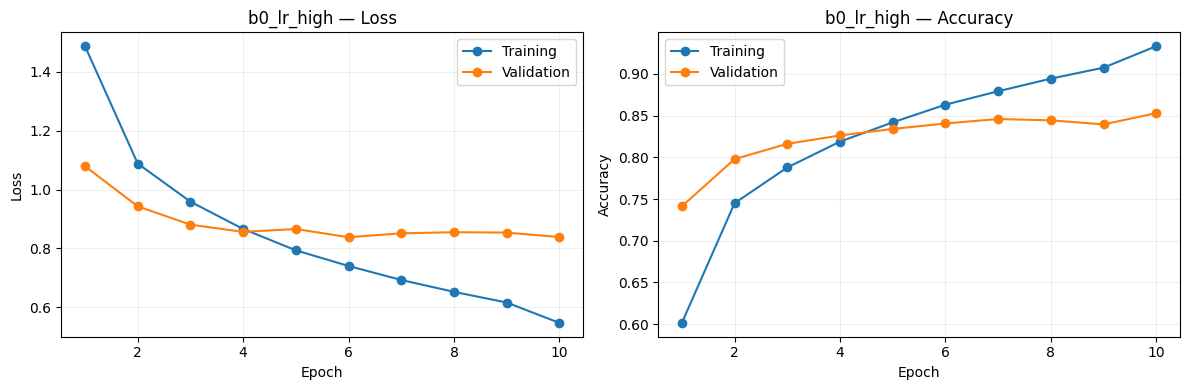

,epoch,train_loss,train_accuracy,val_loss,val_accuracy,minutes
5,6,0.740377,0.863013,0.838043,0.840494,11.03
6,7,0.692807,0.879106,0.851349,0.845805,10.90
7,8,0.652488,0.894184,0.855013,0.844243,10.80
8,9,0.616221,0.907347,0.853771,0.839400,11.12
9,10,0.547081,0.933089,0.838671,0.852835,10.99


In [13]:
if selected_config is not None:
    history_path = paths_for_run(selected_config.name, CHECKPOINT_DIR, REPORT_DIR)['history']
    if history_path.is_file():
        history_df = pd.read_csv(history_path)
        plot_history(history_df, title=selected_config.name,
                     save_path=REPORT_DIR / 'learning_curves.png')
        display(history_df.tail())
else:
    print('Training curves will appear after tuning.')

## 7. Best Model Evaluation

Model dengan validation accuracy tertinggi dimuat kembali dari checkpoint untuk dilakukan evaluasi lebih lanjut.

Evaluasi dilakukan menggunakan classification report dan confusion matrix. Classification report menampilkan precision, recall, dan F1-score untuk setiap kelas, sedangkan confusion matrix digunakan untuk melihat kelas dokumen yang masih sering salah diprediksi.

Validation inference:   0%|          | 0/401 [00:00<?, ?it/s]

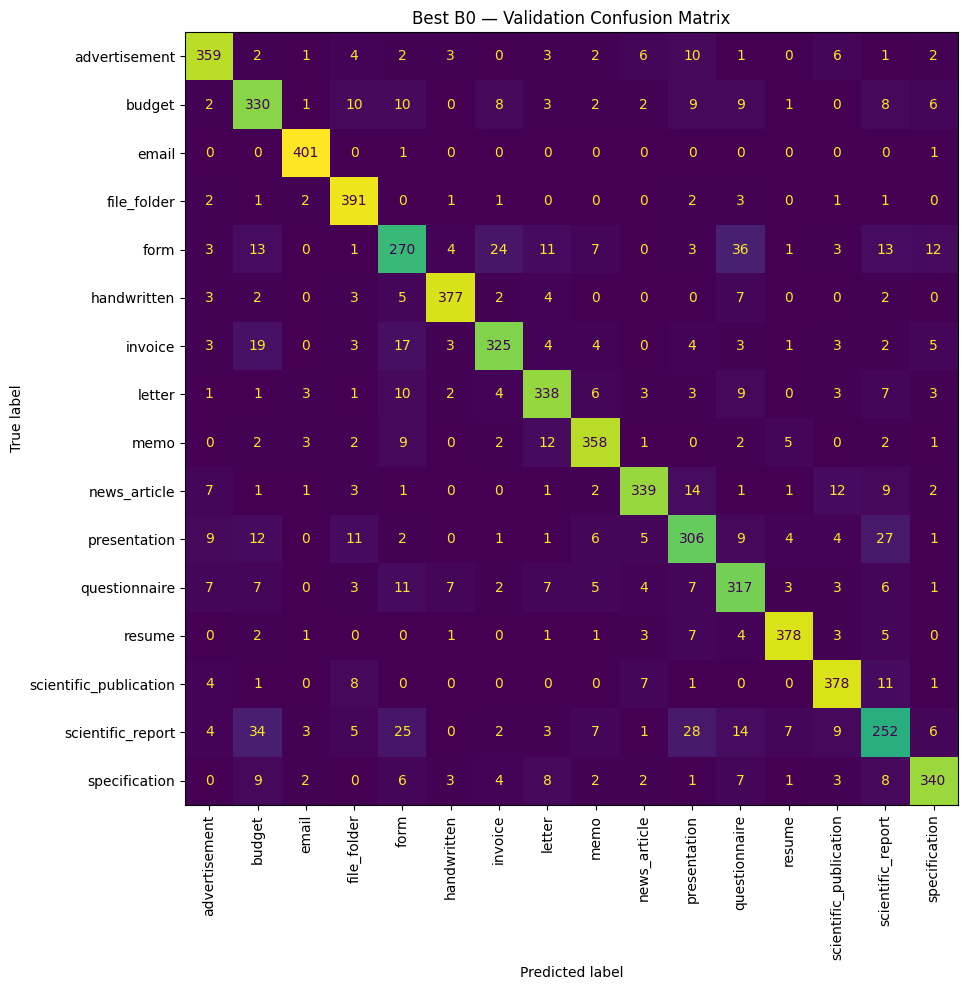

Best checkpoint: /kaggle/working/checkpoints/b0_lr_high_best.pt
Best epoch: 10
Validation accuracy: 85.2835%
Checkpoint best validation: 85.2835%


,precision,recall,f1-score,support
advertisement,0.889,0.893,0.891,402.000
budget,0.757,0.823,0.789,401.000
email,0.959,0.995,0.977,403.000
file_folder,0.879,0.965,0.920,405.000
form,0.732,0.673,0.701,401.000
handwritten,0.940,0.931,0.935,405.000
invoice,0.867,0.821,0.843,396.000
letter,0.854,0.858,0.856,394.000
memo,0.891,0.897,0.894,399.000
news_article,0.909,0.860,0.884,394.000


In [ ]:
if CHECKPOINT_OVERRIDE:
    best_path = Path(CHECKPOINT_OVERRIDE)
else:
    available = [read_experiment_result(c) for c in tuning_configs]
    available = [r for r in available if r is not None]
    best_path = max(available, key=lambda r: r['best_accuracy'])['best_path'] if available else None

if best_path is None or not best_path.is_file():
    print('No fine-tuned checkpoint found. Run training or set CHECKPOINT_OVERRIDE.')
else:
    best_model, best_state = load_model(
        best_path, DEVICE, expected_classes=class_names, expected_split_id=SPLIT_ID)
    if int(best_state.get('image_size', IMAGE_SIZE)) != IMAGE_SIZE:
        raise ValueError('Checkpoint image size differs from validation preprocessing')
    validation_accuracy, classification_df, confusion = evaluate_model(
        best_model, val_loader, DEVICE, class_names, report_dir=REPORT_DIR)
    print('Best checkpoint:', best_path)
    print('Best epoch:', best_state.get('best_epoch', 'not recorded'))
    print(f'Validation accuracy: {validation_accuracy:.4%}')
    print(f"Checkpoint best validation: {float(best_state['best_accuracy']):.4%}")
    display(classification_df.round(3))
    if abs(validation_accuracy - float(best_state['best_accuracy'])) > 0.005:
        raise ValueError('Validation mismatch; check preprocessing and data split.')
    del best_model
    gc.collect()
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()

## 8. Test-Time Augmentation

Setelah memperoleh model terbaik, dilakukan pengujian Test-Time Augmentation (TTA) untuk meningkatkan performa prediksi tanpa melakukan training ulang.

Pengujian dilakukan dengan menggunakan dua ukuran input, yaitu 224 × 224 dan 256 × 256 piksel. Kedua ukuran diproses menggunakan checkpoint model yang sama.

Probabilitas prediksi dari masing-masing ukuran kemudian digabungkan menggunakan weighted averaging. Hasilnya dibandingkan dengan prediksi original pada validation set.

In [ ]:
# 9.1 Multi-Scale Inference Validation

model, _ = load_model(best_path,DEVICE,
    expected_classes=class_names,
    expected_split_id=SPLIT_ID,)

def get_probs(image_size):
    loader = make_loader(
        val_data, TRAIN_ROOT, image_size,
        batch_size=16,training=False,num_workers=0)
    probs = []
    model.eval()
    with torch.inference_mode():
        for images, _ in loader:
            images = images.to(DEVICE)
            with torch.autocast(
                device_type=DEVICE.type,
                enabled=DEVICE.type == "cuda" ):
                outputs = model(images)
            probs.append(
                torch.softmax(outputs.float(), dim=1).cpu())
    return torch.cat(probs).numpy()
p224 = get_probs(224)
p256 = get_probs(256)
p_tta = (p224 + p256) / 2
y_true = val_data["label"].to_numpy()
acc224 = (p224.argmax(axis=1) == y_true).mean()
acc256 = (p256.argmax(axis=1) == y_true).mean()
acc_tta = (p_tta.argmax(axis=1) == y_true).mean()

print(f"Original 224 : {acc224:.4%}")
print(f"Resolution 256: {acc256:.4%}")
print(f"TTA 224 + 256: {acc_tta:.4%}")

Original 224 : 85.2835%
Resolution 256: 84.2993%
TTA 224 + 256: 85.5491%


### 8.1 TTA Weight Comparison

Kombinasi yang diuji adalah 50:50, 70:30, dan 80:20. Tujuannya untuk mengetahui apakah pemberian bobot lebih besar pada resolusi asli 224 piksel dapat meningkatkan validation accuracy.

In [ ]:
# Compare TTA Weights
for w224 in [0.5, 0.7, 0.8]:
    probs = w224 * p224 + (1 - w224) * p256
    acc = (probs.argmax(axis=1) == y_true).mean()
    print(
        f"TTA {w224:.0%} / {1-w224:.0%}: "
        f"Val Acc = {acc:.4%}")

TTA 50% / 50%: Val Acc = 85.5491%
TTA 70% / 30%: Val Acc = 85.6272%
TTA 80% / 20%: Val Acc = 85.6429%


### 8.2 TTA Evaluation

Hasil TTA terbaik dievaluasi menggunakan classification report dan confusion matrix, kemudian dibandingkan dengan hasil prediksi model original.

Berdasarkan pengujian, kombinasi bobot 80% untuk resolusi 224 piksel dan 20% untuk resolusi 256 piksel memberikan validation accuracy tertinggi, yaitu 85.64%.

Nilai tersebut meningkat dibandingkan model original yang memperoleh validation accuracy sebesar 85.28%.

,Method,Validation Accuracy
0,EfficientNet-B0,0.852835
1,EfficientNet-B0 + TTA,0.856429


Classification Report - TTA
                        precision    recall  f1-score   support

         advertisement      0.894     0.898     0.896       402
                budget      0.772     0.825     0.798       401
                 email      0.971     0.995     0.983       403
           file_folder      0.868     0.970     0.916       405
                  form      0.736     0.696     0.715       401
           handwritten      0.947     0.933     0.940       405
               invoice      0.863     0.826     0.844       396
                letter      0.863     0.850     0.857       394
                  memo      0.891     0.900     0.895       399
          news_article      0.911     0.858     0.884       394
          presentation      0.760     0.771     0.766       398
         questionnaire      0.761     0.818     0.789       390
                resume      0.950     0.931     0.940       406
scientific_publication      0.885     0.920     0.902       411
     scient

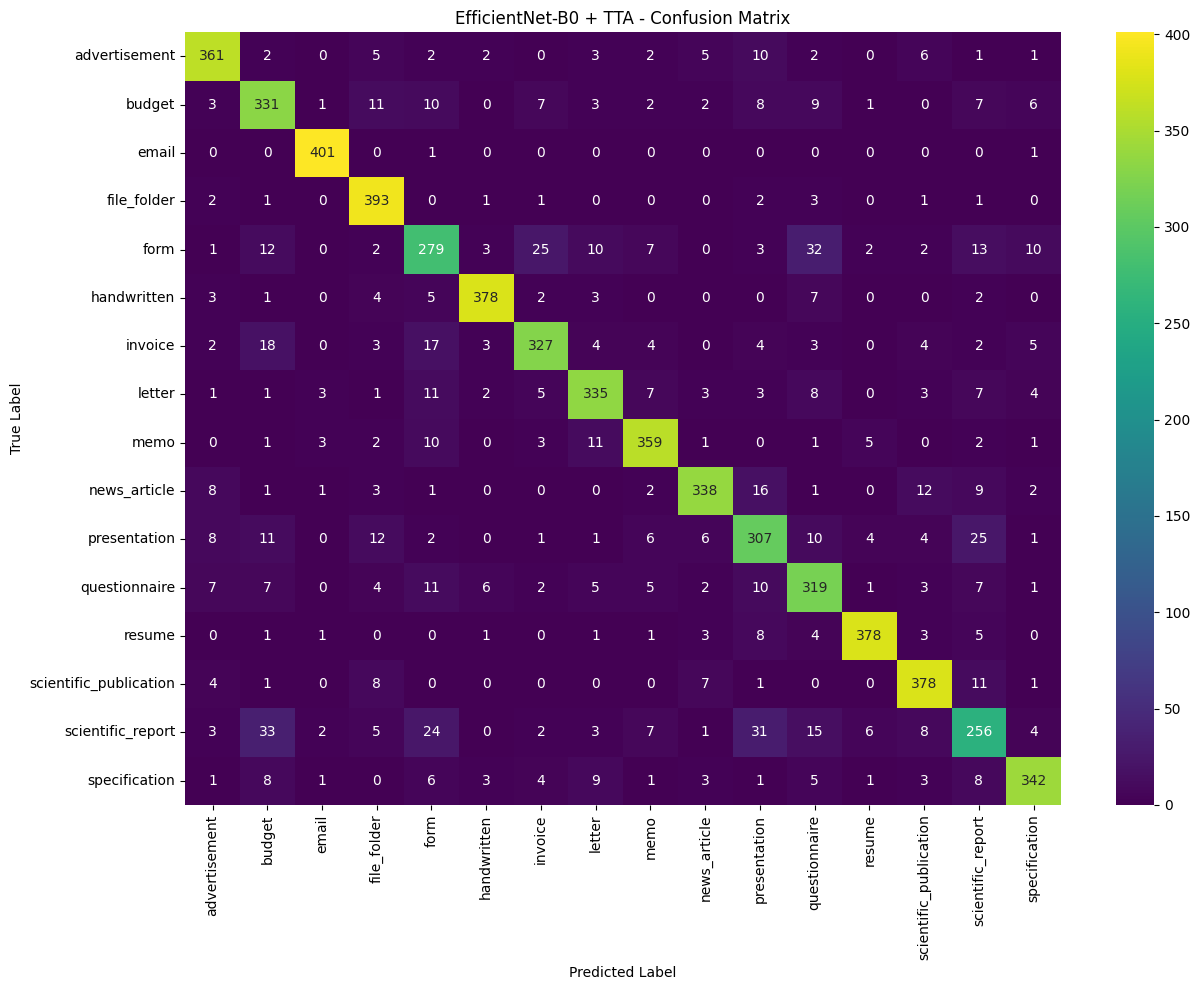

In [ ]:
# TTA Evaluation

# Predictions
original_pred = p224.argmax(axis=1)

tta_probs = 0.8 * p224 + 0.2 * p256
tta_pred = tta_probs.argmax(axis=1)

# Compare accuracy
results = pd.DataFrame({
    "Method": ["EfficientNet-B0", "EfficientNet-B0 + TTA"],
    "Validation Accuracy": [
        np.mean(original_pred == y_true),
        np.mean(tta_pred == y_true)]})
display(results)

# Classification report
print("Classification Report - TTA")
print(classification_report(
    y_true,tta_pred,
    labels=np.arange(len(class_names)),target_names=class_names,
    digits=3,zero_division=0))

# Confusion matrix
cm = confusion_matrix(y_true,tta_pred,
    labels=np.arange(len(class_names)))
plt.figure(figsize=(13, 10))
sns.heatmap(cm,annot=True,
    fmt="d",cmap="viridis",
    xticklabels=class_names,yticklabels=class_names)

plt.title("EfficientNet-B0 + TTA - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 9. Results and Discussion

Model EfficientNet-B0 dengan full fine-tuning menghasilkan validation accuracy terbaik sebesar 85.28% pada epoch ke-10. Hasil ini menunjukkan bahwa pelatihan seluruh backbone dengan learning rate yang sesuai memberikan performa lebih baik dibandingkan pendekatan feature extraction pada eksperimen ini.

Berdasarkan classification report, kategori `email`, `resume`, dan `handwritten` memiliki performa klasifikasi yang baik. Sementara itu, `scientific_report` dan `form` masih menjadi kategori yang cukup sulit dikenali. Beberapa dokumen memiliki struktur dan tata letak yang mirip sehingga model dapat mengalami kesalahan prediksi.

Penggunaan TTA dengan kombinasi resolusi 224 dan 256 piksel meningkatkan validation accuracy dari 85.28% menjadi 85.64%. Peningkatan tersebut menunjukkan bahwa penggabungan probabilitas dari dua ukuran input dapat membantu memperbaiki sebagian prediksi.

Notebook `03_submission.ipynb` akan me-load checkpoint untuk membentuk competition CSV sesuai format.